#### Phase 7 - Intelligent Sensing: Image-Quality Gate

Loads what `src/sensing.py` produced (`models/pca.pkl`, `models/kmeans.pkl`, `results/sensing/`). Nothing is refitted here.

PCA and K-Means are fitted on the training crops; a crop far from every cluster is flagged as an unusual photo.

In [1]:
import sys, json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from sensing import evaluate_sensing, crop_dir
from figures import plot_sensing_histogram

with open(resolve_path(CONFIG["paths"]["sensing_metrics"])) as f:
    metrics = json.load(f)
threshold = metrics["sensing_distance_threshold"]

print("method:   ", metrics["method"])
print(f"PCA: {metrics['pca_n_components']} components kept of {metrics['pca_input_dim']} (95% of training variance)")
print("KMeans cluster sizes:", metrics["kmeans_cluster_sizes"])
print(f"threshold: {threshold:.0f}  ({metrics['selection_rule']})")

method:    PCA(n_components=0.95) then KMeans(n_clusters=3) on flattened grayscale training crops; anomaly score is Euclidean distance to the nearest cluster centroid
PCA: 178 components kept of 42400 (95% of training variance)
KMeans cluster sizes: [336, 180, 284]
threshold: 9911  (mean + 2*std of the validation distance distribution, read off the histogram by inspection (no grid search, no cross-validation, test split not used))


#### The PCA + KMeans space

Each 400×106 grayscale crop becomes 42,400 pixel values. PCA shrinks that to 178 numbers (keeping 95% of the variation), and K-Means groups the 800 training crops into 3 clusters. The plot shows only the first two PCA axes, so the clusters overlap here even though they separate in the full 178 dimensions.

In [2]:
import joblib
from sensing import load_crops, vectors_for

# 1. load the PCA and KMeans that src/sensing.py fitted on the training crops
pca = joblib.load(resolve_path(CONFIG["paths"]["pca_weights"]))
kmeans = joblib.load(resolve_path(CONFIG["paths"]["kmeans_weights"]))

# 2. training crops: 400x106 grayscale, each flattened to a 42,400-value pixel vector
_, train_crops = load_crops("training")
train_vectors = vectors_for(train_crops)                 # (800, 42400)

# 3. project every crop into PCA space: 42,400 values -> 178 component scores
Z = pca.transform(train_vectors)                         # (800, 178)

# 4. KMeans cluster of each crop (computed in all 178 dimensions) and the three centroids
labels = kmeans.predict(Z)                               # (800,)
centroids = kmeans.cluster_centers_                      # (3, 178)

var = pca.explained_variance_ratio_
print(f"crops {train_vectors.shape} -> PCA space {Z.shape}")
print(f"variance kept by {pca.n_components_} components: {var.sum():.2%}  (PC1 {var[0]:.1%}, PC2 {var[1]:.1%})")
for k in range(len(centroids)):
    m = labels == k
    print(f"cluster {k + 1}: n = {m.sum():3d}, mean pixel intensity = {train_vectors[m].mean():.1f}")
print(f"correlation of PC1 with mean pixel intensity: {np.corrcoef(Z[:, 0], train_vectors.mean(axis=1))[0, 1]:.3f}")

crops (800, 42400) -> PCA space (800, 178)
variance kept by 178 components: 95.02%  (PC1 50.5%, PC2 4.5%)
cluster 1: n = 336, mean pixel intensity = 87.8
cluster 2: n = 180, mean pixel intensity = 130.8
cluster 3: n = 284, mean pixel intensity = 55.8
correlation of PC1 with mean pixel intensity: 0.999


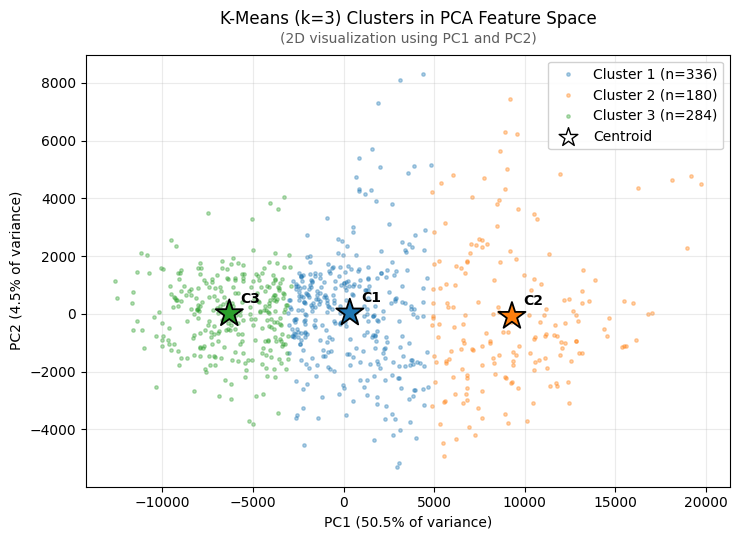

In [3]:
# Plot only the first two of the 178 dimensions. The clustering itself used all 178,
# so clusters can overlap in this 2D view.
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for k in range(len(centroids)):
    m = labels == k
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.35, color=colors[k], label=f"Cluster {k + 1} (n={m.sum()})")
ax.scatter(centroids[:, 0], centroids[:, 1], marker="*", s=420, c=colors,
           edgecolors="black", linewidths=1.3, zorder=5)
for k in range(len(centroids)):
    ax.annotate(f"C{k + 1}", centroids[k, :2], xytext=(8, 8), textcoords="offset points",
                fontsize=10, fontweight="bold")
ax.scatter([], [], marker="*", s=200, c="white", edgecolors="black", label="Centroid")
ax.set_xlabel(f"PC1 ({var[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} of variance)")
ax.set_title(f"K-Means (k={len(centroids)}) Clusters in PCA Feature Space", fontsize=12, pad=22)
ax.text(0.5, 1.02, "(2D visualization using PC1 and PC2)", transform=ax.transAxes,
        ha="center", va="bottom", fontsize=10, color="#5E5E5E")
ax.legend(loc="best", framealpha=0.9)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(resolve_path("results/sensing/pca_kmeans_clusters.png"), dpi=200)   # copy for the report
plt.show()

The three clusters are mostly **brightness bands**: dark (cluster 3, 284 crops, average brightness 56), medium (cluster 1, 336 crops, 88) and bright (cluster 2, 180 crops, 131). PC1 tracks average brightness almost exactly (r = 0.999), which is why the clusters line up left to right. Ordinary crops mainly differ in brightness; the extreme outliers in Section 2 differ for other reasons.

#### 1. The distance distribution and the threshold

validation distance: mean 5787, std 2062 -> mean + 2*std = 9911  (stored threshold: 9911)


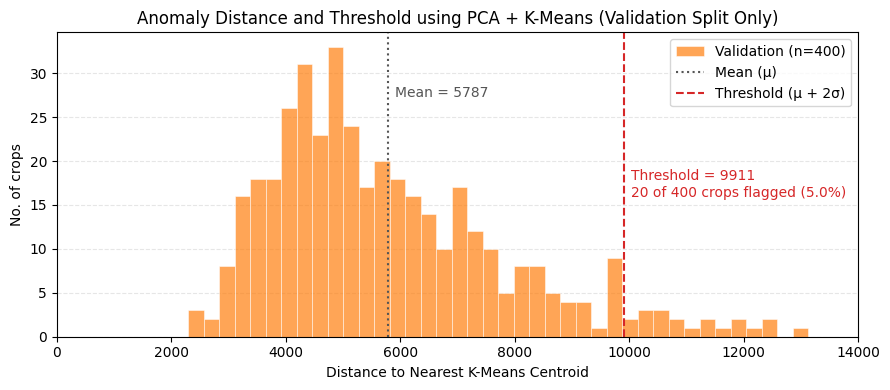

In [4]:
# Anomaly distance of every crop: distance from its PCA projection to the nearest centroid.
def anomaly_distance(vectors):
    return kmeans.transform(pca.transform(vectors)).min(axis=1)

distances = {"training": anomaly_distance(train_vectors)}
for split in ("validation", "testing"):
    _, crops = load_crops(split)
    distances[split] = anomaly_distance(vectors_for(crops))

# Threshold: mean + 2 * std of the VALIDATION distances (test is not used to choose it)
val_d = distances["validation"]
val_mean, val_std = val_d.mean(), val_d.std()
threshold_check = val_mean + 2 * val_std
n_flagged = int((val_d > threshold).sum())
print(f"validation distance: mean {val_mean:.0f}, std {val_std:.0f} -> mean + 2*std = {threshold_check:.0f}"
      f"  (stored threshold: {threshold:.0f})")

# Validation distances only: the split the threshold was chosen from
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(val_d, bins=40, color="#ff7f0e", alpha=0.7, edgecolor="white", linewidth=0.5,
        label=f"Validation (n={len(val_d)})")
ax.axvline(val_mean, color="#555555", linestyle=":", linewidth=1.5, label="Mean (μ)")
ax.axvline(threshold, color="#d62728", linestyle="--", linewidth=1.5, label="Threshold (μ + 2σ)")
ax.annotate(f"Mean = {val_mean:.0f}", xy=(val_mean, 0.8), xycoords=("data", "axes fraction"),
            xytext=(5, 0), textcoords="offset points", color="#555555", fontsize=10, va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.annotate(f"Threshold = {threshold:.0f}\n{n_flagged} of {len(val_d)} crops flagged ({n_flagged / len(val_d):.1%})",
            xy=(threshold, 0.5), xycoords=("data", "axes fraction"), xytext=(5, 0), textcoords="offset points",
            color="#d62728", fontsize=10, va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.set_xlim(0, 14000)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", color="#e6e6e6", linewidth=0.8)
ax.set_xlabel("Distance to Nearest K-Means Centroid")
ax.set_ylabel("No. of crops")
ax.set_title("Anomaly Distance and Threshold using PCA + K-Means (Validation Split Only)", fontsize=12)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

The same threshold on all three splits. The shapes are similar, but test crops sit slightly lower (median 5131 vs. 5739 for training), so fewer test crops are flagged (1.9% vs. 5.0–5.5%, see Section 3).

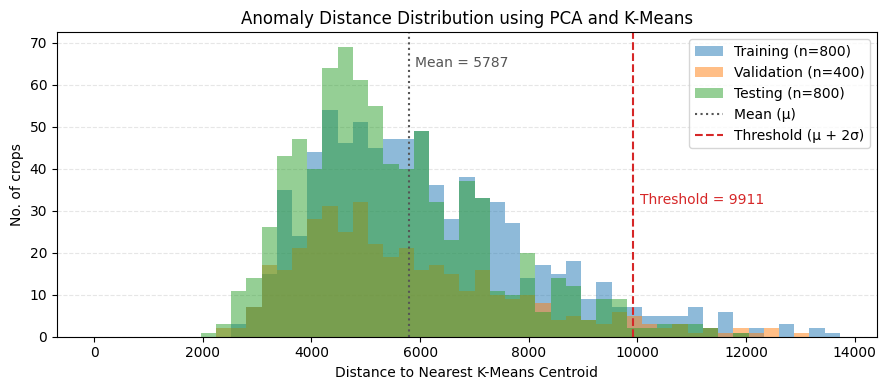

In [5]:
# Histogram of the three splits with the mean and threshold marked (src/figures.py, from the saved
# results/sensing/sensing_scores.csv; evaluate.py saves the same figure for the Inspector)
plot_sensing_histogram()
plt.show()

There is no natural gap, just one long right tail. The threshold (validation μ + 2σ) is a judgement call on where the tail starts. About 5% of validation crops fall past it.

#### 2. Samples of atypical crops

The 12 YOLO-detected crops (validation + test) farthest from the training clusters. Each title shows a **brightness z-score**: how far the crop's average brightness is from the training average, in standard deviations.

*z* = (crop's average brightness − 86.1) / 30.5

(86.1 and 30.5 are the mean and standard deviation of average brightness across the 800 training crops.) *z* near 0 is normal, positive is brighter, negative is darker. |*z*| > 2 (red) means unusually bright or dark.

1192 detected crops scored, 24 flagged (distance > 9911)
top 12: 2 are exposure outliers (|z| > 2), 10 have normal exposure


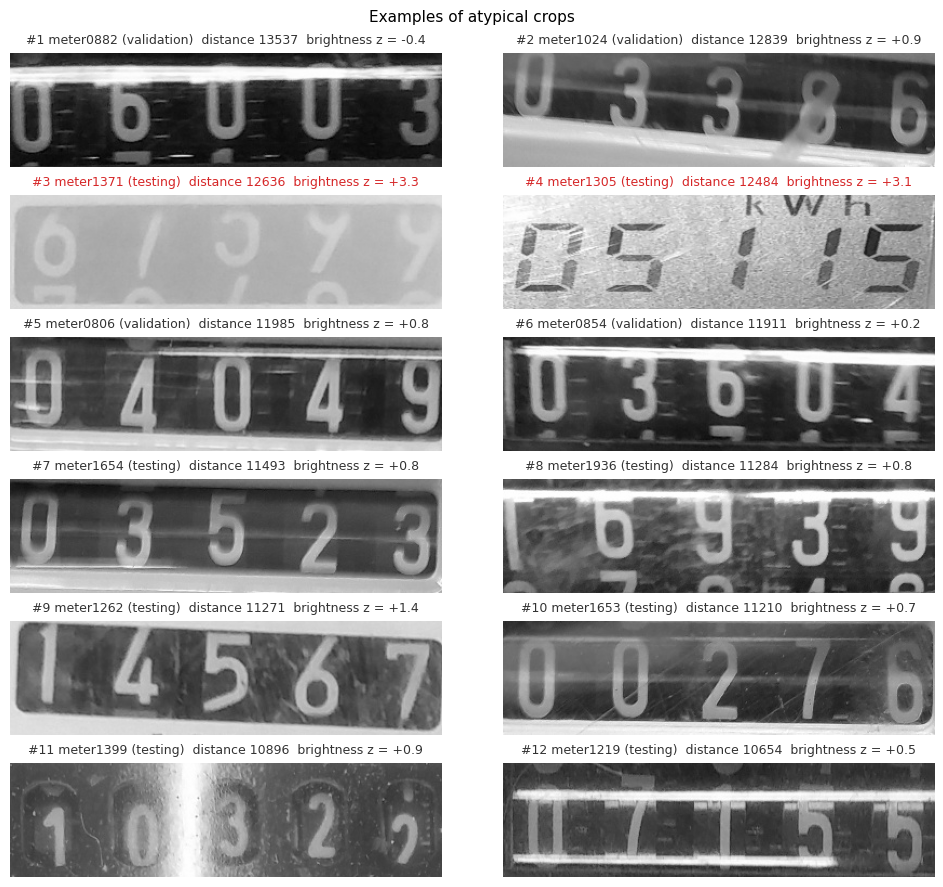

In [6]:
# Rank every detector crop (validation + test) by anomaly distance and show the top ones.
train_px = train_vectors.mean(axis=1)                    # mean pixel intensity of each training crop
px_mu, px_sd = train_px.mean(), train_px.std()

pool = []
for split in ("validation", "testing"):
    names, crops = load_crops(split, "detector")
    vecs = vectors_for(crops)
    for name, crop, dist, mean_px in zip(names, crops, anomaly_distance(vecs), vecs.mean(axis=1)):
        pool.append({"split": split, "name": name, "crop": crop, "distance": dist,
                     "z_exposure": (mean_px - px_mu) / px_sd})   # brightness vs. the training range
pool.sort(key=lambda r: -r["distance"])

n_flagged = sum(r["distance"] > threshold for r in pool)
top = pool[:12]
n_exposure = sum(abs(r["z_exposure"]) > 2 for r in top)
print(f"{len(pool)} detected crops scored, {n_flagged} flagged (distance > {threshold:.0f})")
print(f"top {len(top)}: {n_exposure} are exposure outliers (|z| > 2), {len(top) - n_exposure} have normal exposure")

fig, axes = plt.subplots(6, 2, figsize=(10, 9))
for ax, (rank, r) in zip(axes.ravel(), enumerate(top, start=1)):
    exposure = abs(r["z_exposure"]) > 2
    ax.imshow(r["crop"], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"#{rank} {r['name']} ({r['split']})  distance {r['distance']:.0f}  brightness z = {r['z_exposure']:+.1f}",
                 fontsize=9, color="#d62728" if exposure else "#333333")
fig.suptitle("Examples of atypical crops", fontsize=11)
fig.tight_layout()
plt.show()

**Observation:** Most outliers are not exposure problems. Only 2 of the 12 are red: #3 (`meter1371`, washed out) and #4 (`meter1305`, a different display). The other 10 have normal brightness but show glare bands, scratches or a bright border around the counter.

#### 3. Flag rates per split


In [7]:
rows = []
for split, by_source in metrics["flag_rates"].items():
    for source, r in by_source.items():
        rows.append({"split": split, "crop_source": source, "flagged": r["flagged"], "n": r["n"], "flag_rate": r["flag_rate"]})
display(pd.DataFrame(rows).style.format({"flag_rate": "{:.1%}"}))

,split,crop_source,flagged,n,flag_rate
0,training,ground_truth_crops,44,800,5.5%
1,validation,ground_truth_crops,20,400,5.0%
2,validation,detector_crops,8,395,2.0%
3,testing,ground_truth_crops,15,800,1.9%
4,testing,detector_crops,16,797,2.0%


#### 4. Does the model get flagged crops wrong more often?

**How the error rate is calculated** (ground-truth crops):

1. A crop is **wrong** if any of its five digits is wrong.
2. Split the crops into **flagged** (distance above the threshold) and **passed**.
3. Error rate = wrong crops ÷ crops in the group.

In [8]:
# The error rate built from the raw fused predictions, step by step
score_table = pd.read_csv(resolve_path(CONFIG["paths"]["sensing_scores"]))
score_table = score_table[score_table["crop_source"] == "ground_truth"]

rows = []
for split, key in (("validation", "fusion_val_probs"), ("testing", "fusion_test_probs")):
    z = np.load(resolve_path(CONFIG["paths"][key]))
    probs = np.stack([z[f"digit_{i + 1}_probs"] for i in range(5)], axis=1)            # (n crops, 5 digits, 10 classes)
    truth = np.array([[int(c) for c in r] for r in z["readings"]])                       # true reading, 5 digits
    names = [n.decode() if isinstance(n, bytes) else n for n in z["basenames"]]

    # step 1: a crop is wrong if ANY of its five digits differs from the truth
    wrong = ~(probs.argmax(-1) == truth).all(axis=1)
    # step 2: the sensing flag of each crop (distance > threshold), matched by file name
    flag_of = score_table[score_table["split"] == split].set_index("basename")["flag"]
    flagged = flag_of.loc[names].to_numpy().astype(bool)

    for group, mask in (("Flagged by sensing", flagged), ("Passed by sensing", ~flagged)):
        rows.append({"Split": split.capitalize(), "Group": group,
                     "Crops": int(mask.sum()), "Wrong": int(wrong[mask].sum())})

error_table = pd.DataFrame(rows)
error_table["Error rate"] = error_table["Wrong"] / error_table["Crops"]                  # step 3: wrong ÷ crops
display(error_table.style.format({"Error rate": "{:.1%}"}).hide(axis="index")
        .set_caption("Recognition error rate on ground-truth counter crops"))

Split,Group,Crops,Wrong,Error rate
Validation,Flagged by sensing,20,8,40.0%
Validation,Passed by sensing,380,58,15.3%
Testing,Flagged by sensing,15,9,60.0%
Testing,Passed by sensing,785,140,17.8%


**Observation:** Flagged crops are wrong much more often: 40% vs. 15% on validation (8 of 20 vs. 58 of 380) and 60% vs. 18% on test (9 of 15 vs. 140 of 785), about 2.6× and 3.4×. Only 20 and 15 crops are flagged, so treat the exact percentages as rough.

The gate flags unusual-looking crops, and those are harder for the model, even when a person could read them.

#### 5. The gate on a single crop

`evaluate_sensing(crop)` returns `(distance, flag)`. Below it scores two real crops that YOLO detected: one is flagged, one is approved. Change `samples` to try others.

(APPROVED here only means the sensing check did not flag the crop. The full decision in Phase 8 also needs a confident reading.)

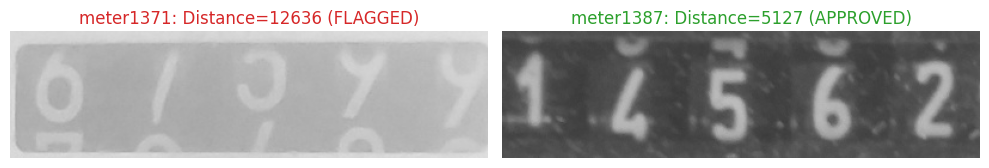

In [9]:
# --- edit these ---
# (split, basename) of crops to score
samples = [("testing", "meter1371"),    # a washed-out crop the gate flags
           ("testing", "meter1387")]    # a typical crop (median distance) that the gate approves
crop_source = "detector"                # "detector" (YOLO box, as in the pipeline) or "ground_truth"
# ------------------

fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 3))
for ax, (split, name) in zip(np.atleast_1d(axes), samples):
    crop = cv2.imread(str(crop_dir(split, crop_source) / f"{name}.jpg"), cv2.IMREAD_GRAYSCALE)
    assert crop is not None, f"no crop named {name} under {crop_dir(split, crop_source)}"
    distance, flag = evaluate_sensing(crop)              # the same call the pipeline makes
    ax.imshow(crop, cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"{name}: Distance={distance:.0f} ({'FLAGGED' if flag else 'APPROVED'})",
                 color="#d62728" if flag else "#2ca02c")
fig.tight_layout()
plt.show()